# Modeloplossing — Checkpoint KMeans & DBSCAN

Dit is de **modeloplossing** van het checkpoint. De bestandsnaam mag niet gewijzigd worden: de checks in `checks/` verwijzen naar dit notebook.

De opgave-versie (`week06/kmeans_dbscan_checkpoint_opgave.ipynb`) heeft dezelfde celstructuur met TODO's die de student invult. Gebruik overal `random_state=42` en `n_init=10` bij KMeans.

## Oefening 1 — Wijn

Cluster de Wine-dataset zo optimaal mogelijk met KMeans. De dataset heeft 13 features op verschillende schalen, dus **schaal eerst met `StandardScaler`**.

Probeer verschillende waarden van `k`, bereken telkens de **silhouette score** en kies de `k` met de hoogste score.

Bewaar je keuze in `best_k_wine` en de bijhorende score in `silhouette_wine`.

In [1]:
import numpy as np
from sklearn import datasets
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

wine = datasets.load_wine()
data = wine.data

# Schaal de data zodat alle features gelijk gewicht krijgen
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

In [2]:
k_range_wine = list(range(2, 8))
sil_scores_wine = []
best_k_wine = 2
best_sil = -1.0
for k in k_range_wine:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(data_scaled)
    sil = silhouette_score(data_scaled, kmeans.labels_)
    sil_scores_wine.append(sil)
    print(f'k = {k} -> silhouette = {sil:.4f}')
    if sil > best_sil:
        best_sil = sil
        best_k_wine = k
silhouette_wine = best_sil
print(f'\nBest k voor Wine: k = {best_k_wine} met silhouette = {silhouette_wine:.4f}')

k = 2 -> silhouette = 0.2683
k = 3 -> silhouette = 0.2849
k = 4 -> silhouette = 0.2517
k = 5 -> silhouette = 0.2272
k = 6 -> silhouette = 0.1958
k = 7 -> silhouette = 0.2091

Best k voor Wine: k = 3 met silhouette = 0.2849


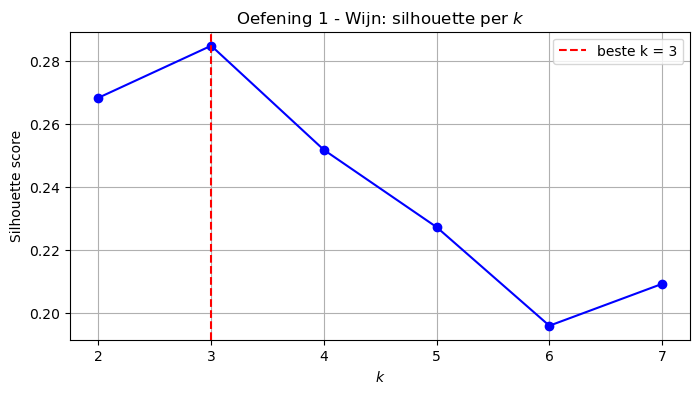

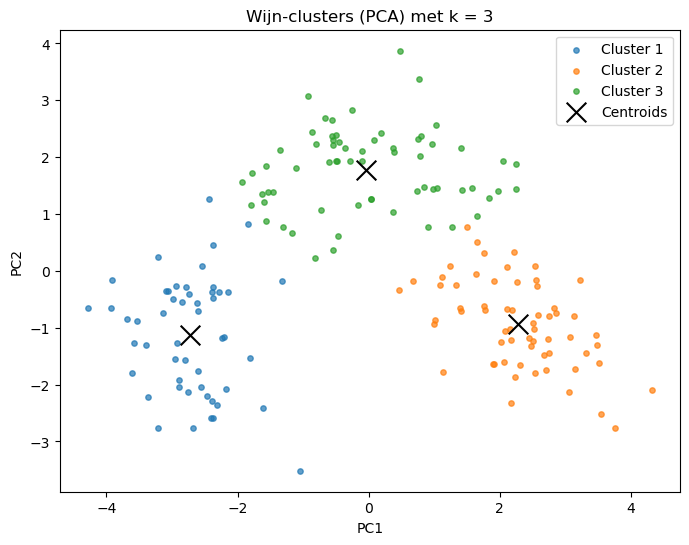

In [3]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# 1) Silhouette-score per k
plt.figure(figsize=(8, 4))
plt.plot(k_range_wine, sil_scores_wine, 'bo-')
plt.axvline(best_k_wine, color='red', linestyle='--', label=f'beste k = {best_k_wine}')
plt.xlabel('$k$')
plt.ylabel('Silhouette score')
plt.title('Oefening 1 - Wijn: silhouette per $k$')
plt.grid()
plt.legend()
plt.show()

# 2) Beste clustering in 2D via PCA (eerste twee hoofdcomponenten)
kmeans_best = KMeans(n_clusters=best_k_wine, random_state=42, n_init=10).fit(data_scaled)
pca = PCA(n_components=2)
data_2d = pca.fit_transform(data_scaled)
centers_2d = pca.transform(kmeans_best.cluster_centers_)

plt.figure(figsize=(8, 6))
for i in range(best_k_wine):
    pts = data_2d[kmeans_best.labels_ == i]
    plt.scatter(pts[:, 0], pts[:, 1], s=15, alpha=0.7, label=f'Cluster {i+1}')
plt.scatter(centers_2d[:, 0], centers_2d[:, 1], c='black', marker='x', s=200, label='Centroids')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title(f'Wijn-clusters (PCA) met k = {best_k_wine}')
plt.legend()
plt.show()

## Oefening 2 — Image Segmentation

We gebruiken clustering om een afbeelding in stukken met gelijkaardige kleuren te verdelen. Gebruik de lokale afbeelding `images/butterfly.jpg` (533×800 pixels, 3 kleurkanalen).

Hervorm de 3D-array tot een `(n_pixels, 3)` matrix met `reshape(-1, 3)`, train dan KMeans met `n_clusters` in `(10, 8, 6, 4, 2)` en vervang elke pixel door de centroidkleur van zijn cluster. Hervorm het resultaat terug naar de originele vorm.

Bewaar het tuple `n_colors = (10, 8, 6, 4, 2)` en de 5 gesegmenteerde afbeeldingen in `segmented_imgs`.

In [4]:
import numpy as np
from PIL import Image
from sklearn.cluster import KMeans

# Gebruik het lokale voorbeeldbeeld (geen download nodig)
image = np.asarray(Image.open('../images/butterfly.jpg'))
print('image shape:', image.shape)

# Hervorm de 3D-array (pixels, breedte, kanalen) naar een (n_pixels, 3) matrix
X = image.reshape(-1, 3)

image shape: (533, 800, 3)


In [5]:
n_colors = (10, 8, 6, 4, 2)
segmented_imgs = []
for n_clusters in n_colors:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10).fit(X)
    segmented_img = kmeans.cluster_centers_[kmeans.labels_]
    segmented_imgs.append(segmented_img.reshape(image.shape))
    print(f'{n_clusters} kleuren: klaar ({len(np.unique(kmeans.labels_))} clusters gebruikt)')

10 kleuren: klaar (10 clusters gebruikt)


8 kleuren: klaar (8 clusters gebruikt)


6 kleuren: klaar (6 clusters gebruikt)


4 kleuren: klaar (4 clusters gebruikt)


2 kleuren: klaar (2 clusters gebruikt)


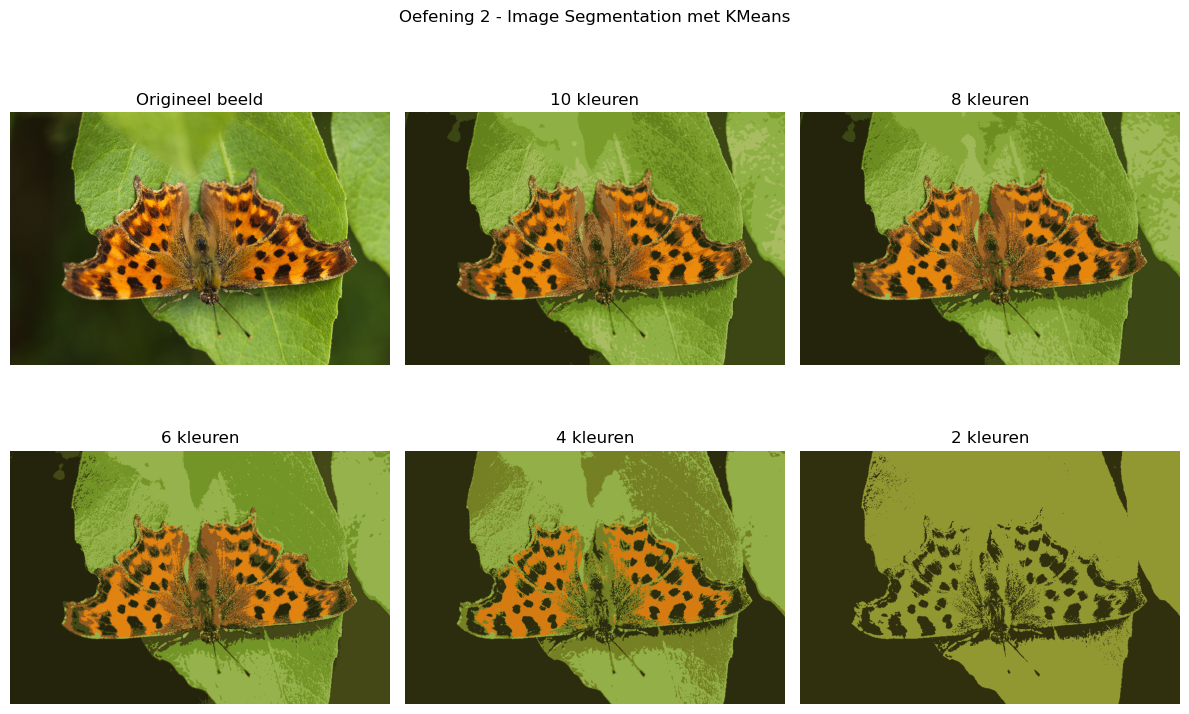

In [6]:
import matplotlib.pyplot as plt

# Toon het origineel en elke gesegmenteerde versie naast elkaar
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.ravel()

axes[0].imshow(image)
axes[0].set_title('Origineel beeld')
axes[0].axis('off')

for idx, n_clusters in enumerate(n_colors):
    axes[idx + 1].imshow(segmented_imgs[idx] / 255)
    axes[idx + 1].set_title(f'{n_clusters} kleuren')
    axes[idx + 1].axis('off')

plt.suptitle('Oefening 2 - Image Segmentation met KMeans')
plt.tight_layout()
plt.show()

## Oefening 3 — KMeans vs DBSCAN op Iris

De Iris-dataset bevat 3 soorten die in de feature-ruimte goed gescheiden, **bolvormige** clusters van **gelijkaardige dichtheid** vormen.

Pas zowel KMeans (verschillende `k`) als DBSCAN (verschillende `eps`/`min_samples`) toe op de **gestandaardiseerde** data en vergelijk met de silhouette score. Bewaar je gekozen `k` in `best_k_iris` en de hoogste silhouette in `silhouette_iris`. Beantwoord daarna vraag 1 in `antwoord_iris`.

In [7]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

iris = load_iris()
data_scaled = StandardScaler().fit_transform(iris.data)

k_range_iris = list(range(2, 6))
sil_scores_iris = []
best_k_iris = 2
best_sil = -1.0
for k in k_range_iris:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(data_scaled)
    sil = silhouette_score(data_scaled, kmeans.labels_)
    sil_scores_iris.append(sil)
    print(f'KMeans k = {k} -> silhouette = {sil:.4f}')
    if sil > best_sil:
        best_sil = sil
        best_k_iris = k
print(f'Beste KMeans voor Iris: k = {best_k_iris}, silhouette = {best_sil:.4f}')

# DBSCAN scoort duidelijk slechter dan KMeans op deze dataset
dbscan_scores = []
best_dbscan_iris = (None, None, -1.0)
for eps in [0.2, 0.3, 0.4, 0.5]:
    for ms in [3, 4, 5]:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(data_scaled)
        if len(np.unique(labels)) > 1:
            sil = silhouette_score(data_scaled, labels)
            dbscan_scores.append((eps, ms, sil))
            if sil > best_dbscan_iris[2]:
                best_dbscan_iris = (eps, ms, sil)
silhouette_iris = best_sil
print(f'Beste DBSCAN voor Iris: eps={best_dbscan_iris[0]}, min_samples={best_dbscan_iris[1]}, '
      f'silhouette={best_dbscan_iris[2]:.4f}')

KMeans k = 2 -> silhouette = 0.5818
KMeans k = 3 -> silhouette = 0.4599
KMeans k = 4 -> silhouette = 0.3869
KMeans k = 5 -> silhouette = 0.3419
Beste KMeans voor Iris: k = 2, silhouette = 0.5818


Beste DBSCAN voor Iris: eps=0.5, min_samples=4, silhouette=0.3646


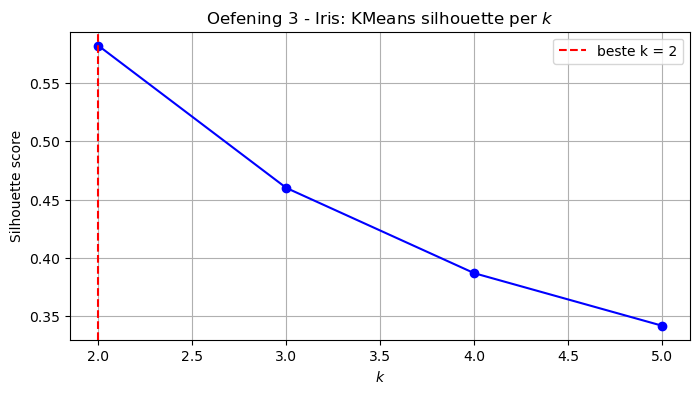

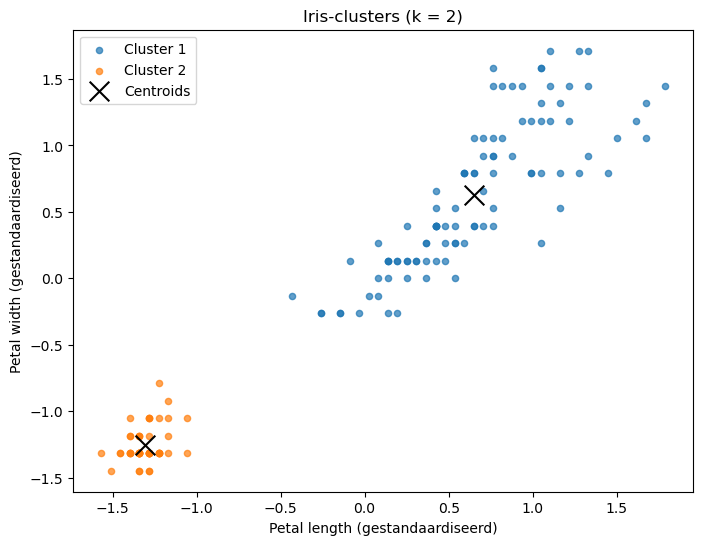

In [8]:
import matplotlib.pyplot as plt

# 1) KMeans silhouette per k
plt.figure(figsize=(8, 4))
plt.plot(k_range_iris, sil_scores_iris, 'bo-')
plt.axvline(best_k_iris, color='red', linestyle='--', label=f'beste k = {best_k_iris}')
plt.xlabel('$k$')
plt.ylabel('Silhouette score')
plt.title('Oefening 3 - Iris: KMeans silhouette per $k$')
plt.grid()
plt.legend()
plt.show()

# 2) Iris-data gekleurd volgens de beste KMeans-clustering
kmeans_best = KMeans(n_clusters=best_k_iris, random_state=42, n_init=10).fit(data_scaled)
plt.figure(figsize=(8, 6))
for i in range(best_k_iris):
    pts = data_scaled[kmeans_best.labels_ == i]
    plt.scatter(pts[:, 2], pts[:, 3], s=20, alpha=0.7, label=f'Cluster {i+1}')
plt.scatter(kmeans_best.cluster_centers_[:, 2], kmeans_best.cluster_centers_[:, 3],
            c='black', marker='x', s=200, label='Centroids')
plt.xlabel('Petal length (gestandaardiseerd)')
plt.ylabel('Petal width (gestandaardiseerd)')
plt.title(f'Iris-clusters (k = {best_k_iris})')
plt.legend()
plt.show()

## Oefening 4 — KMeans vs DBSCAN op Mall

De Mall-dataset (`data/Mall_Customers.csv`) bevat klanten met `Age`, `Annual Income (k$)` en `Spending Score (1-100)`. De clusters hebben **sterk verschillende dichtheden**, waardoor DBSCAN het vaak moeilijk heeft.

Pas KMeans (verschillende `k`) en DBSCAN (verschillende `eps`/`min_samples`) toe op de **gestandaardiseerde** data en vergelijk met de silhouette score. Bewaar je gekozen `k` in `best_k_mall` en de hoogste silhouette in `silhouette_mall`. Beantwoord daarna vraag 2 in `antwoord_dbscan`.

In [9]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

mall = pd.read_csv('../data/Mall_Customers.csv')
features = mall[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]
data_scaled = StandardScaler().fit_transform(features)

k_range_mall = list(range(2, 10))
sil_scores_mall = []
best_k_mall = 5
best_sil = -1.0
for k in k_range_mall:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(data_scaled)
    sil = silhouette_score(data_scaled, kmeans.labels_)
    sil_scores_mall.append(sil)
    print(f'KMeans k = {k} -> silhouette = {sil:.4f}')
    if sil > best_sil:
        best_sil = sil
        best_k_mall = k
print(f'Beste KMeans voor Mall: k = {best_k_mall}, silhouette = {best_sil:.4f}')

# DBSCAN scoort duidelijk slechter (de dichtheden variëren sterk)
dbscan_scores = []
best_dbscan_mall = (None, None, -1.0)
for eps in [0.2, 0.3, 0.4, 0.5]:
    for ms in [5, 10, 15]:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(data_scaled)
        if len(np.unique(labels)) > 1:
            sil = silhouette_score(data_scaled, labels)
            dbscan_scores.append((eps, ms, sil))
            if sil > best_dbscan_mall[2]:
                best_dbscan_mall = (eps, ms, sil)
silhouette_mall = best_sil
print(f'Beste DBSCAN voor Mall: eps={best_dbscan_mall[0]}, min_samples={best_dbscan_mall[1]}, '
      f'silhouette={best_dbscan_mall[2]:.4f}')

KMeans k = 2 -> silhouette = 0.3355
KMeans k = 3 -> silhouette = 0.3578
KMeans k = 4 -> silhouette = 0.4040
KMeans k = 5 -> silhouette = 0.4166
KMeans k = 6 -> silhouette = 0.4284
KMeans k = 7 -> silhouette = 0.4112
KMeans k = 8 -> silhouette = 0.4084
KMeans k = 9 -> silhouette = 0.4201
Beste KMeans voor Mall: k = 6, silhouette = 0.4284


Beste DBSCAN voor Mall: eps=0.5, min_samples=5, silhouette=0.1845


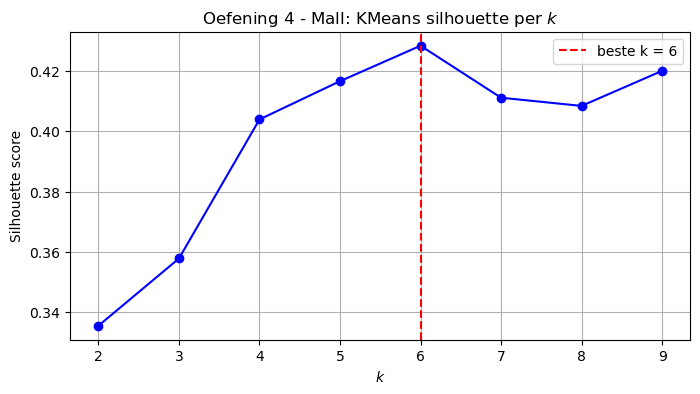

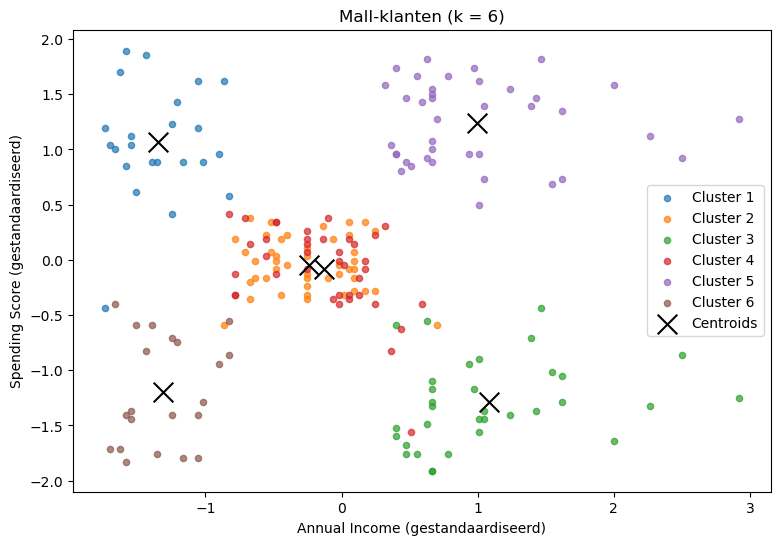

In [10]:
import matplotlib.pyplot as plt

# 1) KMeans silhouette per k
plt.figure(figsize=(8, 4))
plt.plot(k_range_mall, sil_scores_mall, 'bo-')
plt.axvline(best_k_mall, color='red', linestyle='--', label=f'beste k = {best_k_mall}')
plt.xlabel('$k$')
plt.ylabel('Silhouette score')
plt.title('Oefening 4 - Mall: KMeans silhouette per $k$')
plt.grid()
plt.legend()
plt.show()

# 2) Mall-klanten gekleurd volgens de beste KMeans-clustering
kmeans_best = KMeans(n_clusters=best_k_mall, random_state=42, n_init=10).fit(data_scaled)
plt.figure(figsize=(9, 6))
for i in range(best_k_mall):
    pts = data_scaled[kmeans_best.labels_ == i]
    plt.scatter(pts[:, 1], pts[:, 2], s=20, alpha=0.7, label=f'Cluster {i+1}')
plt.scatter(kmeans_best.cluster_centers_[:, 1], kmeans_best.cluster_centers_[:, 2],
            c='black', marker='x', s=200, label='Centroids')
plt.xlabel('Annual Income (gestandaardiseerd)')
plt.ylabel('Spending Score (gestandaardiseerd)')
plt.title(f'Mall-klanten (k = {best_k_mall})')
plt.legend()
plt.show()

## Meerkeuzevragen

### Vraag 1 — Iris
Op de Iris-dataset haalt KMeans een veel hogere silhouette score dan DBSCAN. Wat is de belangrijkste reden?

- **A)** De clusters zijn bolvormig en hebben een gelijkaardige dichtheid, waarvoor KMeans goed geschikt is; DBSCAN kampt met de dichtheidsverschillen.
- **B)** KMeans werkt zonder features te standaardiseren.
- **C)** DBSCAN kan nooit meer dan 2 clusters vinden.
- **D)** KMeans kent het aantal clusters op voorhand, en dat is altijd beter.

Bewaar je antwoord (`"A"`, `"B"`, `"C"` of `"D"`) in `antwoord_iris`.

### Vraag 2 — DBSCAN
Wanneer is DBSCAN een betere keuze dan KMeans?

- **A)** Wanneer de clusters een onregelmatige, niet-bolvormige vorm hebben of er outliers/ruis zijn.
- **B)** Wanneer alle clusters bolvormig en even groot zijn.
- **C)** Wanneer je altijd precies `k` clusters nodig hebt.
- **D)** Wanneer de dataset klein is en je snel wilt clusteren.

Bewaar je antwoord (`"A"`, `"B"`, `"C"` of `"D"`) in `antwoord_dbscan`.

In [11]:
# Vraag 1: de iris-clusters zijn bolvormig en gelijkaardig dicht -> KMeans scoort beter.
antwoord_iris = "A"

# Vraag 2: DBSCAN is beter bij niet-bolvormige clusters, verschillende dichtheden of outliers.
antwoord_dbscan = "A"
